# Sesión 3 — Laboratorio: agrupamiento jerárquico de Iris

Demostración del agrupamiento jerárquico aglomerativo con SciPy sobre el conjunto Iris
(150 flores, cuatro medidas en centímetros). La especie **no** se usa para agrupar:
sólo para evaluar al final.

Pasos: construir el árbol, elegir dónde cortarlo, comparar criterios de enlace,
leer un dendrograma y comparar con k-medias (Sesión 2).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist

## Paso 1: construir el árbol

Como en la Sesión 2, se usan las medidas en centímetros sin estandarizar: todas tienen
la misma unidad y los pétalos son las variables más informativas.

(149, 4)


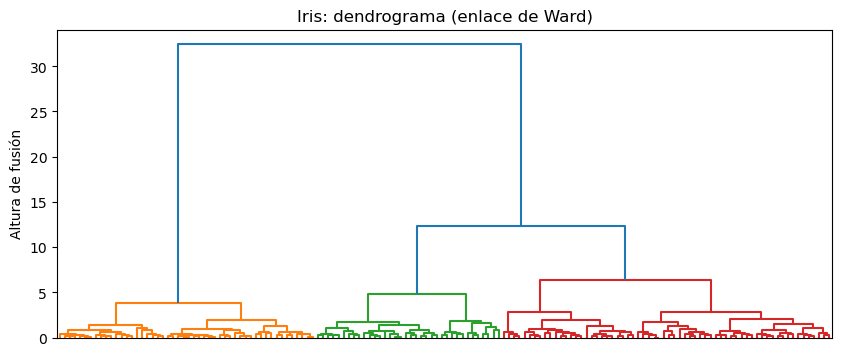

In [2]:
iris = load_iris()
X, especie = iris.data, iris.target

Z = linkage(X, method="ward")     # una fila por fusión: [grupo i, grupo j, altura, tamaño]
print(Z.shape)

fig, ax = plt.subplots(figsize=(10, 4))
dendrogram(Z, no_labels=True, color_threshold=10, ax=ax)
ax.set_ylabel("Altura de fusión")
ax.set_title("Iris: dendrograma (enlace de Ward)")
plt.show()

## Paso 2: dónde cortar

Un salto grande entre las alturas de fusiones consecutivas indica que se están uniendo
grupos muy distintos.

Alturas de las 6 últimas fusiones: [ 2.87  3.83  4.85  6.4  12.3  32.45]


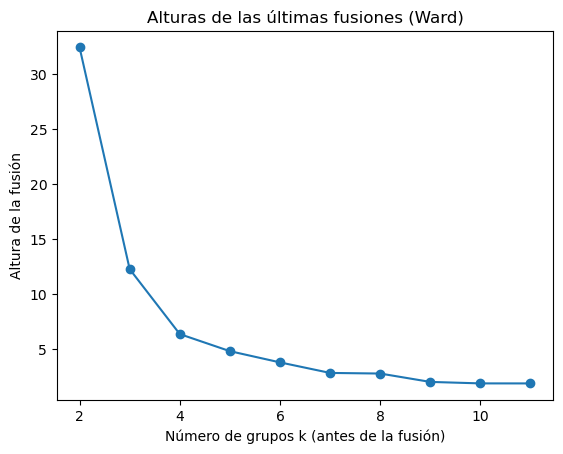

In [3]:
print("Alturas de las 6 últimas fusiones:", Z[-6:, 2].round(2))

alturas = Z[::-1, 2][:10]
plt.plot(range(2, 12), alturas, "o-")
plt.xlabel("Número de grupos k (antes de la fusión)")
plt.ylabel("Altura de la fusión")
plt.title("Alturas de las últimas fusiones (Ward)")
plt.show()

## Paso 3: comparar los criterios de enlace

Para cada enlace: correlación cofenética (qué tan bien conserva el árbol las distancias
originales) y, cortando en 3 grupos, el índice de Rand ajustado contra la especie.

In [4]:
filas = []
for metodo in ["single", "complete", "average", "ward"]:
    Z_m = linkage(X, method=metodo)
    c, _ = cophenet(Z_m, pdist(X))
    z = fcluster(Z_m, t=3, criterion="maxclust")
    filas.append({"enlace": metodo,
                  "correlación cofenética": round(c, 3),
                  "ARI contra la especie": round(adjusted_rand_score(especie, z), 3),
                  "tamaños": sorted(np.bincount(z)[1:].tolist(), reverse=True)})
pd.DataFrame(filas)

,enlace,correlación cofenética,ARI contra la especie,tamaños
0,single,0.864,0.564,"[98, 50, 2]"
1,complete,0.727,0.642,"[72, 50, 28]"
2,average,0.877,0.759,"[64, 50, 36]"
3,ward,0.873,0.731,"[64, 50, 36]"


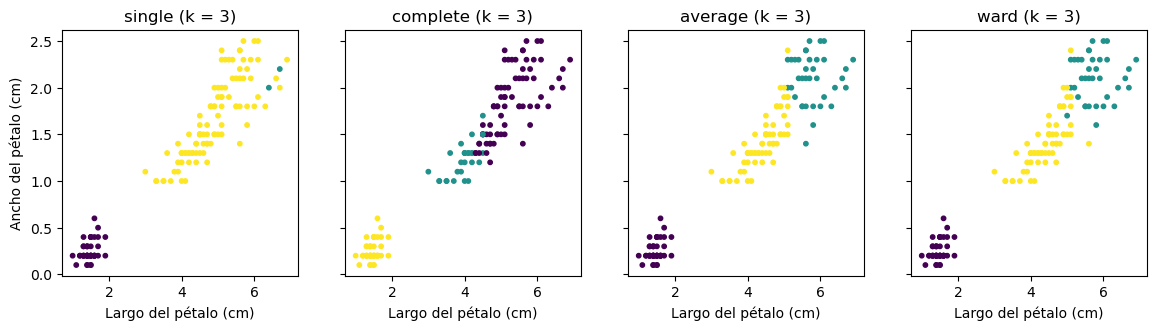

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
for ax, metodo in zip(axes, ["single", "complete", "average", "ward"]):
    z = fcluster(linkage(X, method=metodo), t=3, criterion="maxclust")
    ax.scatter(X[:, 2], X[:, 3], c=z, cmap="viridis", s=10)
    ax.set_title(f"{metodo} (k = 3)")
    ax.set_xlabel("Largo del pétalo (cm)")
axes[0].set_ylabel("Ancho del pétalo (cm)")
plt.show()

## Paso 4: leer el dendrograma

Un dendrograma de 30 flores (10 por especie) permite leer las hojas. La especie sólo se
usa para nombrar las hojas.

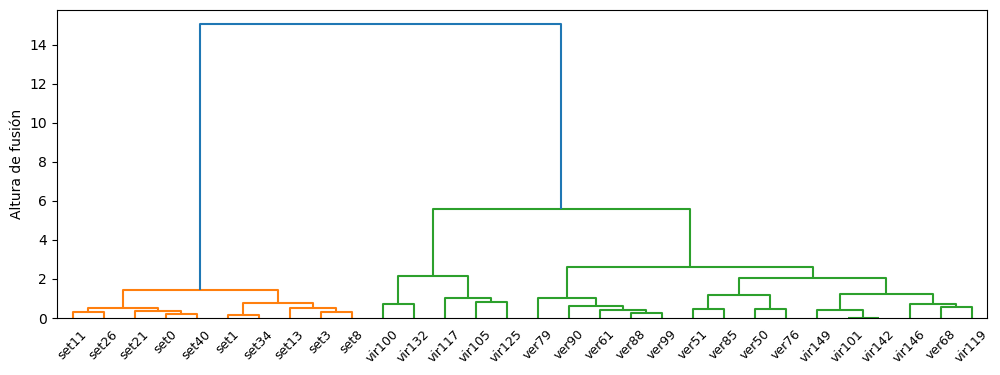

k = 2
col_0  set  ver  vir
row_0               
1       10    0    0
2        0   10   10

k = 3
col_0  set  ver  vir
row_0               
1       10    0    0
2        0    0    5
3        0   10    5



In [6]:
rng = np.random.default_rng(0)
idx = np.sort(np.concatenate([rng.choice(np.where(especie == e)[0], 10, replace=False)
                              for e in range(3)]))
nombres = np.array(["set", "ver", "vir"])
etiquetas = [f"{nombres[e]}{i}" for i, e in zip(idx, especie[idx])]

Z30 = linkage(X[idx], method="ward")
fig, ax = plt.subplots(figsize=(12, 4))
dendrogram(Z30, labels=etiquetas, leaf_font_size=9, ax=ax)
ax.set_ylabel("Altura de fusión")
plt.show()

for k in (2, 3):
    z = fcluster(Z30, t=k, criterion="maxclust")
    print(f"k = {k}"); print(pd.crosstab(z, nombres[especie[idx]]), end="\n\n")

## Paso 5: comparar con k-medias

Ward une en cada paso los grupos que menos aumentan la inercia: es una versión voraz del
objetivo de k-medias.

In [7]:
z_ward = fcluster(linkage(X, "ward"), t=3, criterion="maxclust")
z_km = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(X)

print(pd.crosstab(z_ward, z_km, rownames=["Ward"], colnames=["k-medias"]))
print("ARI Ward vs. k-medias:", round(adjusted_rand_score(z_ward, z_km), 3))
print("ARI Ward vs. especie:", round(adjusted_rand_score(especie, z_ward), 3))
print("ARI k-medias vs. especie:", round(adjusted_rand_score(especie, z_km), 3))
pd.crosstab(z_ward, iris.target_names[especie], rownames=["Ward"], colnames=["especie"])

k-medias   0   1   2
Ward                
1          0  50   0
2          0   0  36
3         62   0   2
ARI Ward vs. k-medias: 0.961
ARI Ward vs. especie: 0.731
ARI k-medias vs. especie: 0.73


especie,setosa,versicolor,virginica
Ward,,,
1,50,0,0
2,0,1,35
3,0,49,15


## Conclusiones

- Un solo dendrograma muestra las dos escalas de Iris: setosa contra el resto, y después
  versicolor contra virginica.
- Los saltos en las alturas de fusión orientan la elección de *k* sin recalcular nada.
- El enlace importa: simple encadena, completo resume mal las distancias, y promedio y
  Ward dan los grupos más útiles.
- Ward reproduce casi exactamente el resultado de k-medias, sin depender de una inicialización.
- Ningún método separa por completo versicolor y virginica: sus medidas se traslapan.